In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from IPython.display import Latex, Markdown, display_latex, display_markdown

# +
%matplotlib inline
# -

# First Order Systems
## Autonomous Systems
$$
\dot{y} = y(y - 1)(2 - y),\ y \geq 0
$$

### Find all equilibrium concentrations (a)
$$
\dot{y} = 0 \rightarrow y = 0, 1, 2
$$

### Plot the phase line on the $(y,\dot{y})$-plane (b)

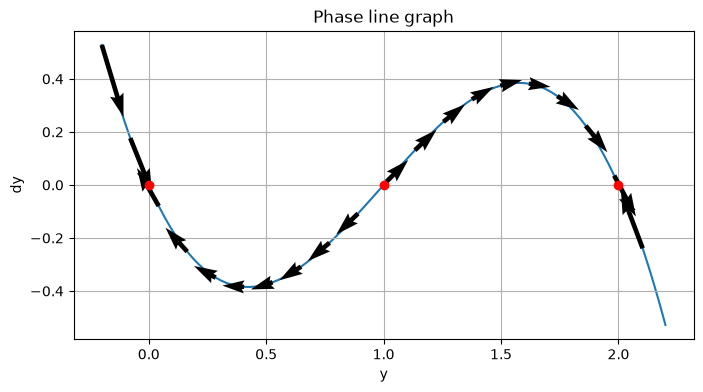

In [2]:
plt.figure(figsize=(8, 4))
plt.title("Phase line graph")


def fn1(y):
    return y * (y - 1) * (2 - y)


y = np.linspace(-0.2, 2.2, 100)
dy = fn1(y)

plt.plot(y, dy, zorder=1)

eq_y = np.array([0, 1, 2])
eq_dy = fn1(eq_y)

plt.scatter(eq_y, eq_dy, color="red", zorder=3)

step = 5
y = y[::step]
dy = dy[::step]
ddy = -3 * y**2 + 6 * y - 2

flow_dir = np.sign(dy)
u = flow_dir
v = ddy * flow_dir

plt.quiver(y, dy, u, v, zorder=2)

plt.xlabel("y")
plt.ylabel("dy")
plt.grid(True)
plt.show()

### Classify each equilibrium as a source or sink based on the direction of the arrows on your phase line (c)
$$
y = 0 \rightarrow \text{sink/stable}
$$

$$
y = 1 \rightarrow \text{source/unstable}
$$

$$
y = 2 \rightarrow \text{sink/stable}
$$

### Based on your phase line, explain briefly why this system exhibits bistable behavior (d)
This is a bistable system given there are two states that are considered stable for the system.
One can think of this as a light switch where it'll either be on or off.
It could get stuck in the middle, but any small disturbance will take it back to either of the two.

## Non-Autonomous Systems
$$
\dot{y} = -ty
$$

### Use the classic "separate and integrate" technique to obtain the general solution to the ODE(2)
$$
\begin{align}
    \frac{dy}{dt} &= -ty \\
    \int y^{-1} dy &= -\int t \,dt \\
    \ln(y) &= -\frac{1}{2} t^{2} + C\\
    y &= Ce^{-\frac{1}{2} t^{2}}
\end{align}
$$

### Plot a slope field on the $(t, y)$-plane (3, 4)

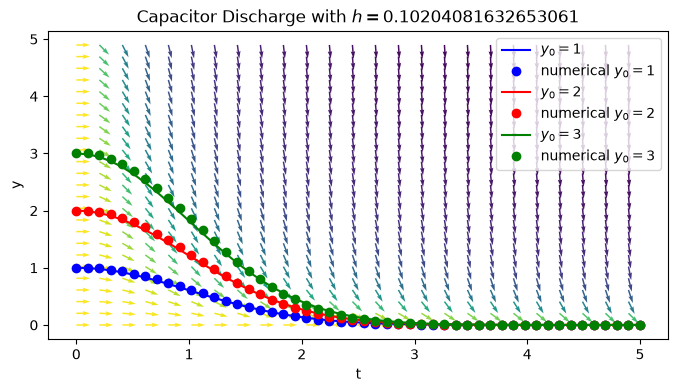

In [3]:
plt.figure(figsize=(8, 4))


def diff_fn2(t, y):
    return -t * y


def num_solve(t_range, y_init, h):
    output = np.zeros_like(t_range)
    output[0] = y_init

    for i in range(len(t_range) - 1):
        t = t_range[i]
        y = output[i]
        output[i + 1] = y + h * diff_fn2(t, y)

    return output


def fn2(t, C):
    return C * np.exp(-(1 / 2) * t**2)


t = np.linspace(0, 5)
y = np.linspace(0, 5)

h = t[1] - t[0]
plt.title(f"Capacitor Discharge with $h = {h}$")

y_1 = fn2(t, 1)
plt.plot(t, y_1, color="blue", label="$y_0 = 1$")
plt.plot(t, num_solve(t, 1, h), "bo", label="numerical $y_0 = 1$")

y_2 = fn2(t, 2)
plt.plot(t, y_2, "red", label="$y_0 = 2$")
plt.plot(t, num_solve(t, 2, h), "ro", label="numerical $y_0 = 2$")

y_3 = fn2(t, 3)
plt.plot(t, y_3, color="green", label="$y_0 = 3$")
plt.plot(t, num_solve(t, 3, h), "go", label="numerical $y_0 = 3$")

step = 2
T, Y = np.meshgrid(t[::step], y[::step])

dT = np.ones_like(T)
dY = diff_fn2(T, Y)
M = np.hypot(dT, dY)

arrow_length = 0.2
dT = arrow_length * (dT / M)
dY = arrow_length * (dY / M)

plt.quiver(T, Y, dT, dY, dT)

plt.xlabel("t")
plt.ylabel("y")
plt.legend()
plt.show()

# Linear Dynamical Systems
## Equilibrium Points (1)
Since these systems are homogeneous linear, the equilibrium
$Ax = \vec{0}$ can only have solution $x = \vec{0}$.
This is because all 6 matrices have $\det(A) \neq 0$.

In [4]:
# System matrices
A1 = sp.Matrix([[0, 1], [-2, -3]])
A2 = sp.Matrix([[0, 1], [-2, 3]])
A3 = sp.Matrix([[0, 1], [-5, -2]])
A4 = sp.Matrix([[0, 1], [-5, 2]])
A5 = sp.Matrix([[0, 1], [-1, 0]])
A6 = sp.Matrix([[0, 1], [1, 0]])

matrices = [A1, A2, A3, A4, A5, A6]

for i, mat in enumerate(matrices):
    det = sp.det(mat)
    display_latex(Latex(f"$\\det(A_{i + 1}) = {det}$"))

## Eigen Values, Eigen Vectors and Classification (2, 3)

In [5]:


def classify(eigen_vals):
    if len(eigen_vals["real"]) == 2:
        a, b = eigen_vals["real"]

        if a < 0 and b < 0:
            return "Stable Node"

        elif a > 0 and b > 0:
            return "Unstable Node"

        elif sp.sign(a) != sp.sign(b):
            return "Saddle"

        return "None"

    elif len(eigen_vals["complex"]) == 2:
        a, b = eigen_vals["complex"]

        if sp.conjugate(a) != b:
            return "None"

        if sp.re(a) < 0 and sp.re(b) < 0:
            return "Stable Spiral"

        elif sp.re(a) > 0 and sp.re(b) > 0:
            return "Unstable Spiral"

        elif sp.re(a) == 0 and sp.re(b) == 0:
            return "Center"

        return "None"

    else:
        return "None"


for i, mat in enumerate(matrices):
    eigen_vals = {"real": [], "complex": []}

    latex_out = f"$$A_{i + 1} \\rightarrow"

    eigen_vecs = mat.eigenvects()
    for j, (eigval, mult, eigvect) in enumerate(eigen_vecs):
        latex_out += f"\\lambda_{j} = {sp.latex(eigval)}, \\ "
        latex_out += f"\\vec{{\\lambda_{j}}} = {sp.latex(eigvect[0])} \\ "

        if eigval.is_real:
            eigen_vals["real"].append(eigval)
        else:
            eigen_vals["complex"].append(eigval)

    latex_out += "\\rightarrow \\text{{" + classify(eigen_vals) + "}}$$"

    display_latex(Latex(latex_out))

## Pointcare Trace Diagram Interpretation (4)

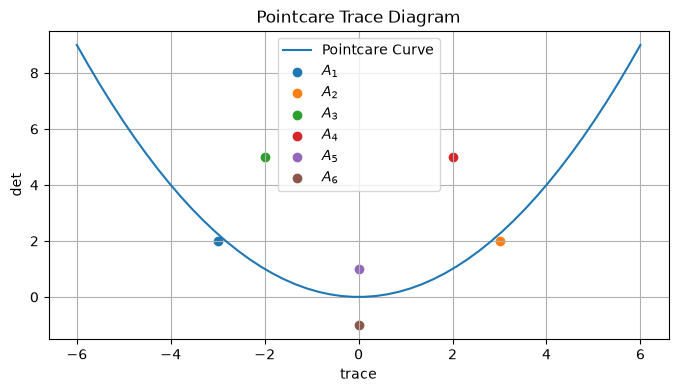

In [6]:
plt.figure(figsize=(8, 4))
plt.title("Pointcare Trace Diagram")
plt.grid(True)

trace = np.linspace(-6, 6)
det_curve = trace**2 / 4

plt.plot(trace, det_curve, label="Pointcare Curve")

for i, mat in enumerate(matrices):
    mat_trace = mat.trace()
    mat_det = float(mat.det().evalf())  # pyright: ignore[reportAttributeAccessIssue]

    plt.scatter(mat_trace, mat_det, label=f"$A_{{{i + 1}}}$")

plt.xlabel(r"trace")
plt.ylabel(r"det")
plt.legend()
plt.show()

### $A_1$
For this system, it can be seen in both eigen values ($a,b \in R$ \& a,b < 0) that the system is converging towards stability at the origin.
Similarly, the location of the trace and determinant of the matrix, it is considered a sink.
This means that all trajectories of that flavor will converge at the origin over the long term.

In a more physical interpretation, the spring mass will eventually remain still without the need to oscilate (unlike other systems I'll discuss later).
This would be more commonly described as an overdamped system.

### $A_2$
Unlike $A_1$, this system will never converge to the equilibrium point. This can be seen in the source node categorization.

In the context of our spring mass, this means that the spring mass will be only stable if the state is equilibrium, but the moment it is disturbed it will move further from it over time.
This would be more commonly described as exponential growth.

### $A_3$
This would be considered an underdamped system.
The core features here can be seen in the spiral sink categorization and the negative real parts of the eigenvalues.
This means that it will eventually converge at the origin, but the oscillatory nature of the eigenvalues help characterize the fact that it will oscillate as it approaches equilibrium.

### $A_4$
Like $A_2$, this is exponential growht.
However, the key distinction is it's similarity with $A_3$ in that it will oscillate as it exponentially grows in magnitude.

### $A_5$
This would be an undamped system.
Given there are no real parts in the eigen values, it will continue to oscillate as no energy is being removed or added from the system.

### $A_6$
This system would be seen as a semi-stable system.
This is due to the system not exponentially growing but it having a state where it converges to the origin while having another one where it grows away from the origin.
This would be the case of a spring that pushes outwards instead of inwards, therefore whenever it can achieve equilibrium it gets pushed away.

## Analytical Solutions using the Matrix Exponential (5)

$$
\dot{x} = Ax \rightarrow x(t) = e^{At}x_0
$$

$$
x_0 = \begin{bmatrix}
q_0 \\ v_0
\end{bmatrix}
$$

In [7]:
for i, mat in enumerate(matrices):
    P, D = mat.diagonalize()
    P_inv = P.inv()

    display_markdown(Markdown(f"### System $A{i + 1}$"))
    display_latex(
        Latex(f"""$$
        x(t) = {sp.latex(P)}e^{{{sp.latex(D)}t}}{sp.latex(P_inv)} x_0
        $$""")
    )

    t = sp.symbols("t", real=True)
    q0, v0 = sp.symbols("q_0 v_0", real=True)
    x0 = sp.Matrix([q0, v0])

    exp_Dt = D.applyfunc(lambda entry, t=t: sp.exp(entry * t))
    exp_At = P * exp_Dt * P_inv
    x_t = sp.simplify(exp_At * x0)

    display_latex(
        Latex(f"""$$
        x(t) = {sp.latex(x_t)}
        $$""")
    )

### System $A1$

### System $A2$

### System $A3$

### System $A4$

### System $A5$

### System $A6$

## Vector fields, Phase portraits and Eigen vector directions (6, 7, 8)

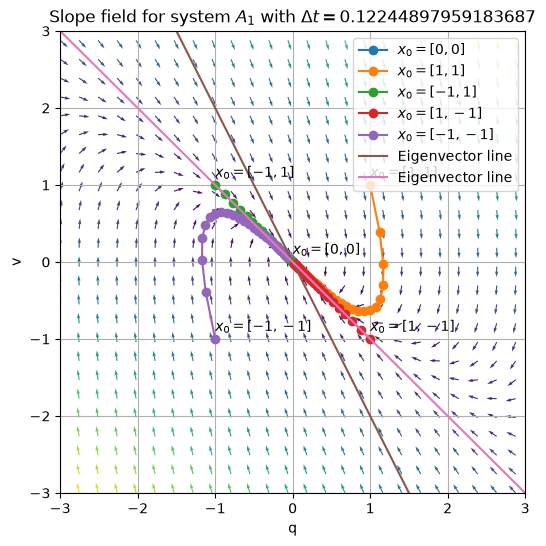

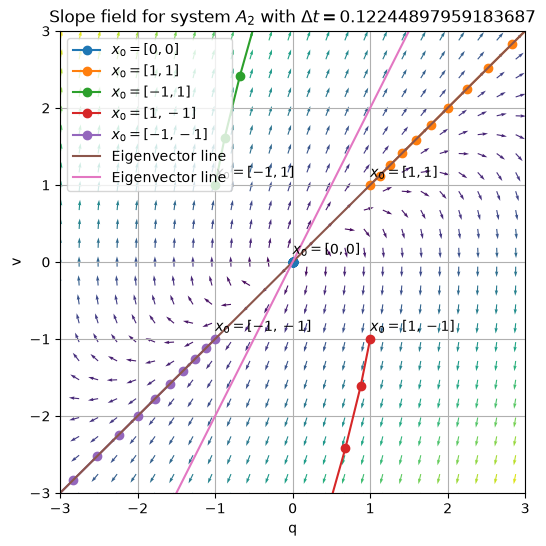

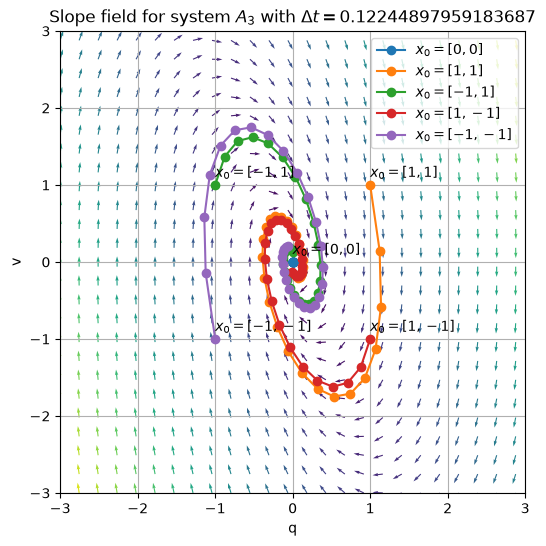

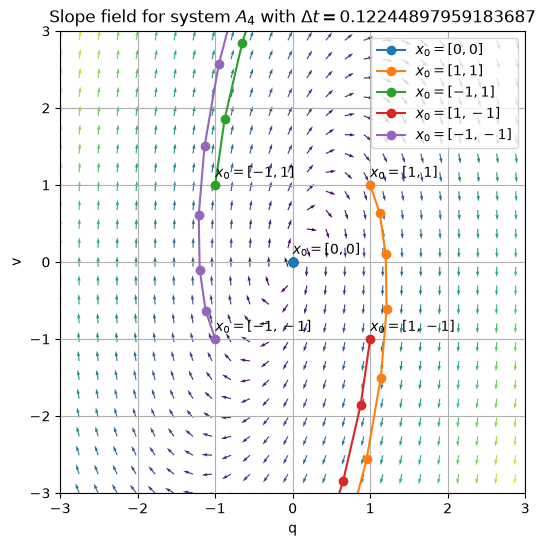

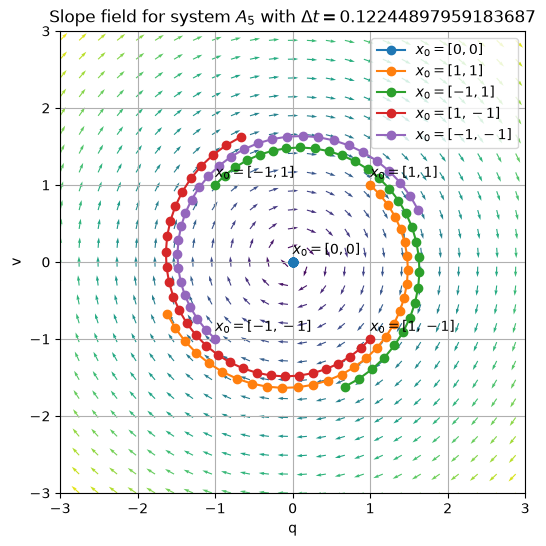

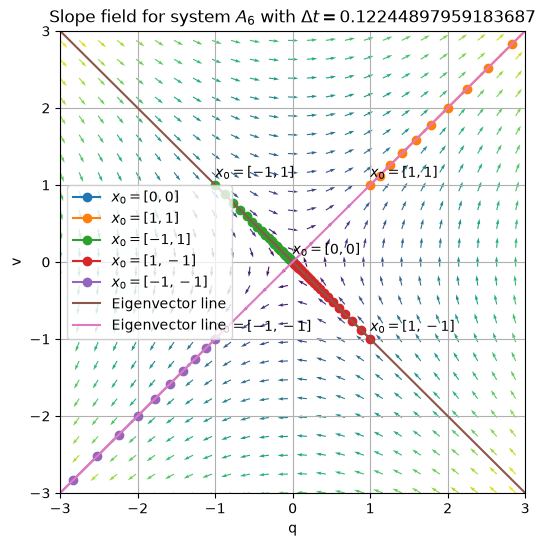

In [8]:


def solve_path(A, h, x_0, step_count):
    output = [0] * step_count
    output[0] = x_0

    for i in range(step_count - 1):
        x_n = output[i]
        output[i + 1] = x_n + h * A @ x_n

    return np.array(output)


def matrix_slope_field(i, A, x_inits, eigvecs, name=None):
    q = np.linspace(-3, 3)
    v = np.linspace(-3, 3)

    step = 2
    Q, V = np.meshgrid(q[::step], v[::step])
    U = A[0, 0] * Q + A[0, 1] * V
    UV = A[1, 0] * Q + A[1, 1] * V

    M = np.sqrt(U**2 + UV**2)
    M[M == 0] = 1.0

    U_unit = V / M
    V_unit = UV / M

    h = q[1] - q[0]

    plt.figure(figsize=(6, 6))
    if name is None:
        plt.title(f"Slope field for system $A_{i + 1}$ with $ \\Delta t = {h}$")
    else:
        plt.title(f"{name} with $ \\Delta t = {h}$")

    plt.quiver(Q, V, U_unit, V_unit, M)

    step_count = 30
    for x_0 in x_inits:
        points = solve_path(A, h, np.array(x_0), step_count)
        plt.plot(points[:, 0], points[:, 1], marker="o", label=f"$x_0 = {x_0}$")

        plt.text(x_0[0], x_0[1] + 0.1, f"$x_0 = {x_0}$")

    for eigvec in eigvecs:
        if eigvec is not None:
            s = np.linspace(-3, 3)
            plt.plot(s * eigvec[0], s * eigvec[1], label="Eigenvector line")

    plt.xlim(-3, 3)
    plt.ylim(-3, 3)
    plt.xlabel("q")
    plt.ylabel("v")
    plt.grid(True)
    plt.legend()
    plt.show()


x_inits = [[0, 0], [1, 1], [-1, 1], [1, -1], [-1, -1]]

for i, mat in enumerate(matrices):
    eig_data = mat.eigenvects()
    eigvecs = []
    for eig_val, mult, eig_vec in eig_data:
        if eig_val.is_real:
            eigvecs.append(sp.matrix2numpy(eig_vec[0], dtype=float))
        else:
            eigvecs.append(None)

    matrix_slope_field(i, sp.matrix2numpy(mat, dtype=float), x_inits, eigvecs)

### Eigen Vector Interpretation (8)
#### Real Eigen Values
##### $A_1$
As both values are real negative, one can see how the vectors represent the direction of pull towards the origin.
The magnitude of the respective eigenvalue is also respective to how strongly they pull towards the origin.

##### $A_2$
It is the same as it is for $A_1$ but instead of pulling it is pushing outwards from the origin.

##### $A_6$
As it has real eigenvalues of different signs, one can see that for the positive eigenvalue it pushes outwards from the origin and then the negative eigenvalue pushes towards the origin.
This is further reinforced by the numerical solutions.

#### Complex Eigen Values
In the case for these matrices, we can't visualize a complex vector in our 2D plane.
However, from the complex terms, we can evaluate that there will be rotation about the origin.
The real part just like in the entirely real cases defines the decay or growth.
The complex part here dictates the oscillation speed.
The eigen vector describes how based on those 2 properties, the spiral will be morphed into the shapes we see in the graphs.

## Analytical vs Numerical Solution, Euler integration and $\Delta t$ (9, 12)
For this I decided to go with a matrix $A_5$ as there is no growth or decay. This will be particularly useful at showing how the numerical method is adding energy via its error.

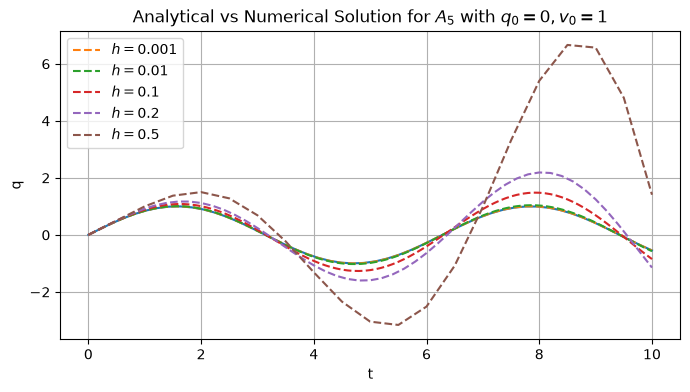

In [9]:


def spring_sol(t, q0, v0):

    q_t = q0 * (1 - np.exp(1j)) ** 2 + 1j * v0 * (1 - np.exp(2j * t))

    v_t = (
        1j * q0 * np.exp(2j * t)
        - 1j * q0
        + v0 * np.exp(2j * t)
        + 2 * v0 * np.exp(1j * t)
        + v0
    )

    q_t *= (1 / 2) * np.exp(-1j * t)
    v_t *= (1 / 2) * np.exp(-1j * t)

    return np.real(q_t), np.real(v_t)


def spring_numerical_sol(h, x_0, end):
    t_num = np.linspace(0, end, int(end / h) + 1)
    return t_num, solve_path(sp.matrix2numpy(A5), h, x_0, len(t_num))


q0 = 0
v0 = 1
end = 10

steps = [0.001, 0.01, 0.1, 0.2, 0.5]

t = np.linspace(0, end)
q, v = spring_sol(t, q0, v0)

plt.figure(figsize=(8, 4))
plt.title(f"Analytical vs Numerical Solution for $A_5$ with $q_0 = {q0}, v_0 = {v0}$")

plt.plot(t, q)
for step in steps:
    t_num, sol_num = spring_numerical_sol(step, np.array([q0, v0]), end)
    plt.plot(t_num, sol_num[:, 0], linestyle="--", label=f"$h = {step}$")

plt.xlabel("t")
plt.ylabel("q")
plt.grid(True)
plt.legend()
plt.show()

As it can be seen in the picture above, as $\Delta t$ grows, the error and phase offset grow.
This is coming from the error of the function over time which is accumulating into energy and showing that exponential amplitude growth.
This can also be seen in the phase portraits above as the orbits of the numerical solutions are not perfect circles for $A_6$ while the slope field is a perfect circle.
While the numerical solution encompasses the oscillatory nature, it fails to capture the stability of a system.

## Stiffness, damping and instability (10, 11)
### $A_1$
$$
k = 2, c = 3
$$

This system doesn't oscillate as the damping is stronger than the spring.

### $A_2$
$$
k = 2, c = -3
$$

This system exponentially grows because the spring is constantly pushing away and that overpowers the damping.

### $A_3$
$$
k = 5, c = 2
$$

This system oscillates because the spring is stronger than the damping.
However, it will eventually converge as energy is removed by the damping.

### $A_4$
$$
k = 5, c = -2
$$

This system oscillates because the spring is stronger than the damping.
However, it exponentially grows as the damping is adding energy to the system instead of removing it.

### $A_5$
$$
k = 1, c = 0
$$

This system oscillates forever because the spring is undamped.
This means that the system doesn't lose energy, which means that the mass will oscillate forever.

### $A_6$
$$
k = -1, c = 0
$$

Like the other systems that exponentially grow, this one has a spring that is constantly pushing away.
Therefore, this oscillation continues to gather energy no matter what, making it highly unstable.

## Euler integration and timestep
Note: Check the earlier segment on the simulation as I discussed the same points as I did here.

The key take away from a growing $\Delta t$ is that the energy in the system will be corrupted someties by non-existing energy loss or gain.
This means that the system will either grow over time or will damp itself when numerically solved.
In the case of $A_5$, it can be seen how the energy is added as the amplitude grows over time.

# Non-linear pendulum
## Analytical Analysis
### State-space formulation (13)
$$
\begin{align}
    \ddot{\theta} &= -\sin(\theta) \\
    \begin{bmatrix}
        \dot{\theta} \\ \dot{\omega}
    \end{bmatrix}
    &=
    \begin{bmatrix}
        0 & 1 \\
        -\frac{sin(\theta)}{\theta} & 0
    \end{bmatrix}
    \begin{bmatrix} 
        \theta \\ \omega
    \end{bmatrix}
\end{align}
$$

### Equilibria (14)
$$
\begin{align}
    \ddot{\theta} &= 0 \\
    -\sin(\theta) &= 0 \\
    \sin(\theta) &= 0 \\
    \theta &= \arcsin(0) \\
    \theta &= 0, k\pi \leftarrow k \in Z \\
    \text{Down Eq}: k &= 2n, n \in Z \\
    \text{Up Eq}: k &= 2n + 1, n \in Z \\
\end{align}
$$

### Jacobian (15)
To get $J$, just get the derivatives of $\ddot{\theta}$ with respect to $\theta$ and $\dot{\theta}$
$$
J = \begin{bmatrix}
    0 & 1 \\
    -\cos(\theta) & 0
\end{bmatrix}
$$

### Linearization (16)
$$
J_0 = \begin{bmatrix}
    0 & 1 \\
    -1 & 0
\end{bmatrix}
$$
$$
J_{\pi} = \begin{bmatrix}
    0 & 1 \\
    1 & 0
\end{bmatrix}
$$

 
### Local Stability (17)
$$
\text{eigvals}(J_0) = -i, i
$$
Given that a pendulum will oscillate at the bottom, it makes sense that we get the complex eigven values for this equilibrium point.
Additionally, as there is no damping, there is no real part just like in the linear system analysis we conducted before.

$$
\text{eigvals}(J_{\pi}) = -1, 1
$$
As an inverted pendulum can be kept in balance if perfectly upright, the negative value represents the pendulum's ability to remain still.
However, if mildly toppled the pendulum will be moving away from this equilibrium point. This is what the positive eigen value represents.

### Vector Field and Trajectories (18, 19)

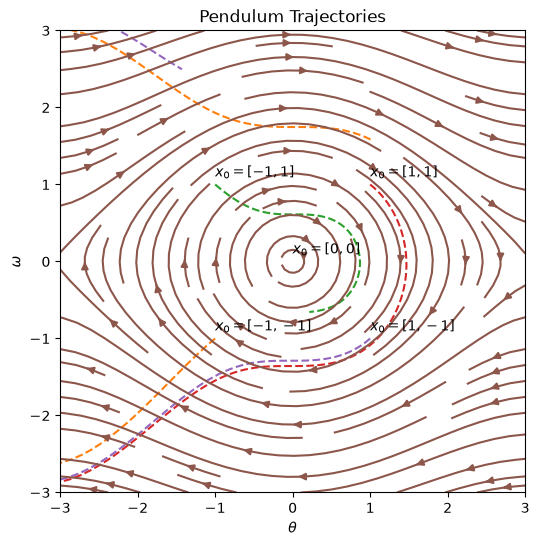

In [10]:


def mat_pendulum(x):
    return np.array([[0, 1], [-np.sin(x[0]), 0]])


def solve_pendulum(A, h, x_0, step_count):
    output = [0] * step_count
    output[0] = x_0

    for i in range(step_count - 1):
        x_n = output[i]
        output[i + 1] = x_n + h * A(x_n) @ x_n

    return np.array(output)


x_inits = [[0, 0], [-1, -1], [-1, 1], [1, 1], [1, -1]]

theta = np.linspace(-3, 3)
omega = np.linspace(-3, 3)
Theta, Omega = np.meshgrid(theta, omega)

dTheta = Omega
dOmega = -np.sin(Theta)

plt.figure(figsize=(6, 6))
plt.title("Pendulum Trajectories")

h = 0.05
step_count = 100
for x_0 in x_inits:
    points = solve_pendulum(mat_pendulum, h, np.array(x_0), step_count)
    plt.plot(points[:, 0], points[:, 1], linestyle="--", label=f"$x_0 = {x_0}$")

    plt.text(x_0[0], x_0[1] + 0.1, f"$x_0 = {x_0}$")

plt.streamplot(Theta, Omega, dTheta, dOmega)

plt.xlabel(r"$\theta$")
plt.ylabel(r"$\omega$")
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.show()

### Comparison (20)

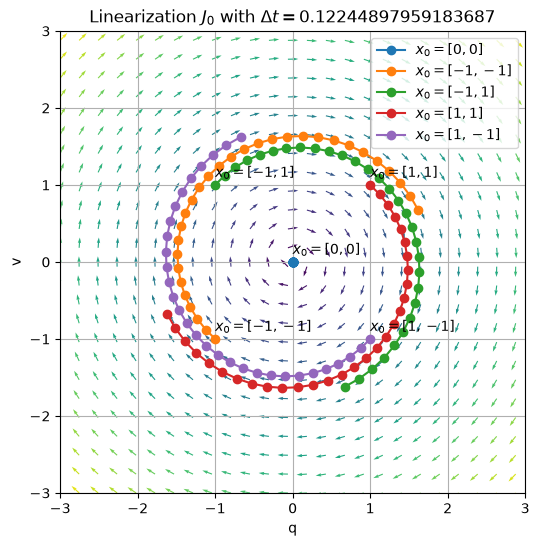

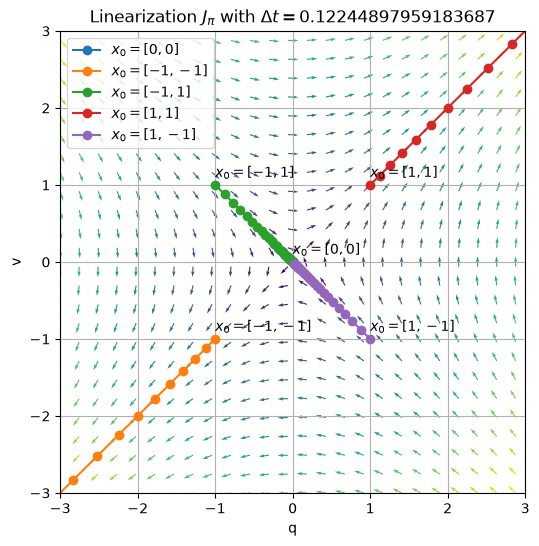

In [11]:
j0 = np.array([[0, 1], [-1, 0]], dtype=float)
matrix_slope_field(0, j0, x_inits, [], "Linearization $J_0$")

jP = np.array([[0, 1], [1, 0]], dtype=float)
matrix_slope_field(0, jP, x_inits, [], "Linearization $J_{\\pi}$")

So by looking at the linearizations vs the real graph, it can be seen that the linearizations happen to become distrorted at extreme cases.
More specifically, the cases where there is another equilibrium point nearby.
For example, look at the path of $x_0 = (1,1)$, the better linearization for this case is $J_0$ as the path more closely resembles that of the slope field.
In the case of the points further away, as $x \rightarrow \pi$ it can be seen how the $J_0$ approximation preserves the oscillation while the actual system doesn't.
This would be a good use for the $J_{\pi}$ linearization instead.